<a href="https://colab.research.google.com/github/Panlyzar/project_suui2/blob/main/SUI_CV6__Z%C3%A1klady_neuronov%C3%BDch_s%C3%AD%C5%A5%C3%AD_MNIST.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 📒 CVIČENÍ 6. -  Základy neuronových síťí
## 🎱 MNIST DEMO
---
V tomto **demonstrátoru** si ukážeme jak si neuronová síť poradí s *MNIST* datasetem - ručně psané číslice. A zda dokáže **rozpoznat ty naše**.






In [ ]:
# Import základních ML knihoven - best practices
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# Knihovny TensorFlow pro práci s neuronovými sítěmi
import tensorflow as tf

## 📃 ČÁST 1: Příprava dat: MNIST (Modified National Institute of Standards and Technology)
---

**📘 Popis**
**MNIST** je klasický dataset používaný pro trénink a testování algoritmů **strojového učení**, zejména v oblasti **rozpoznávání rukopisných číslic**.  
Obsahuje **rukou psané číslice 0–9** extrahované z formulářů amerického úřadu NIST a normalizované do jednotného formátu.

Dataset je považován za *"Hello World"* úlohu pro hluboké učení.

---

**🧩 Struktura a formát dat**
- **Počet vzorků:**  
  - Trénovací sada: `60 000` obrázků  
  - Testovací sada: `10 000` obrázků  
- **Rozměr obrázků:** `28 × 28` pixelů  
- **Počet kanálů:** `1` (odstíny šedi)  
- **Rozsah hodnot pixelů:** `0–255` (často normalizováno na `0–1`)  
- **Datový typ:** `uint8`  
- **Formát:**  
  - `train-images-idx3-ubyte` – trénovací obrázky  
  - `train-labels-idx1-ubyte` – trénovací štítky  
  - `t10k-images-idx3-ubyte` – testovací obrázky  
  - `t10k-labels-idx1-ubyte` – testovací štítky

---

**🔢 Třídy (labely)**
Dataset obsahuje **10 tříd**, odpovídajících číslicím:
| Label | Popis |
|:------:|:------|
| 0 | Číslice „0“ |
| 1 | Číslice „1“ |
| 2 | Číslice „2“ |
| 3 | Číslice „3“ |
| 4 | Číslice „4“ |
| 5 | Číslice „5“ |
| 6 | Číslice „6“ |
| 7 | Číslice „7“ |
| 8 | Číslice „8“ |
| 9 | Číslice „9“ |

---


In [ ]:
# Import MNIST datasetu
import tensorflow as tf
import matplotlib.pyplot as plt

# Načtení MNIST datasetu
(train_images, train_labels), (test_images, test_labels) = tf.keras.datasets.mnist.load_data()

11490434/11490434 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


In [ ]:
# Definice funkce která převádí pole na obrázek
from PIL import Image

def arr_to_bmp(array_data, mode="RGB"):
  img = Image.fromarray(array_data, mode).resize((64,64))
  return img

### 🔭 Explorační analýza
*Není třeba provádět důkladnou analýzu, jedná se o čistý dataset.*

In [ ]:
# Zkontrolujeme shape a počet dat
train_images.shape, test_images.shape

((60000, 28, 28), (10000, 28, 28))

In [ ]:
train_images.ndim, test_images.ndim

(3, 3)

In [ ]:
train_labels.shape, test_labels.shape

((60000,), (10000,))

✍ *Vsuvka:* Všimnite si tvaru vstupních dat - `train_images`. Mají tvar `(60000, 28, 28)`, což značí 60000 obrázků, 28 pixelů / řádek, 28 pixelů / sloupec a 1 kanál na pixel (BW).

In [ ]:
# Podíváme se na čistý náhlad vzorků dat
train_images[0]

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,
         18,  18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 170,
        253, 253, 253, 253, 253, 225, 172, 253, 242, 195,  64,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  49, 238, 253, 253, 253, 253,
        253, 253, 253, 253, 251,  93,  82,  82,  56,  39,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  18, 219, 253, 253, 253, 253,
        253, 198, 182, 247, 241,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  80, 156, 107, 253, 253,
        205,  11,   0,  43, 154,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,  14,   1, 154, 253,
         90,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0, 139, 253,
        190,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  11, 190,
        253,  70,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  35,
        241, 225, 160, 108,   1,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         81, 240, 253, 253, 119,  25,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  45, 186, 253, 253, 150,  27,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,  16,  93, 252, 253, 187,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0, 249, 253, 249,  64,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,  46, 130, 183, 253, 253, 207,   2,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  39,
        148, 229, 253, 253, 253, 250, 182,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  24, 114, 221,
        253, 253, 253, 253, 201,  78,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  23,  66, 213, 253, 253,
        253, 253, 198,  81,   2,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  18, 171, 219, 253, 253, 253, 253,
        195,  80,   9,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,  55, 172, 226, 253, 253, 253, 253, 244, 133,
         11,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0, 136, 253, 25

/tmp/ipython-input-2857302831.py:5: DeprecationWarning: 'mode' parameter is deprecated and will be removed in Pillow 13 (2026-10-15)
  img = Image.fromarray(array_data, mode).resize((64,64))


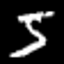

In [ ]:
arr_to_bmp(train_images[0], mode="L")

In [ ]:
train_labels[0]

np.uint8(5)

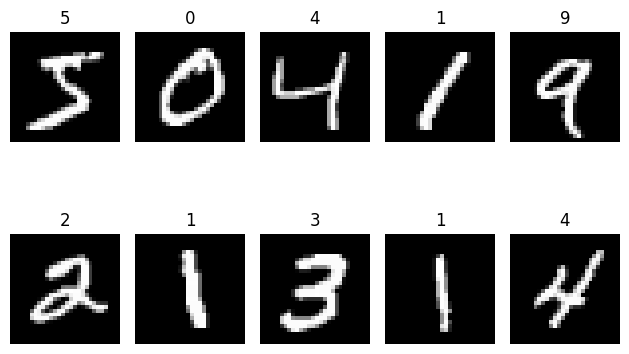

In [ ]:
# Náhled dat - vizualizace (prvních 10)
for i in range(10):
    plt.subplot(2, 5, i+1)
    plt.imshow(train_images[i], cmap='gray')
    plt.title(f'{train_labels[i]}')
    plt.axis('off')

# Zarovná layout
plt.tight_layout()

## ✂️ Rozdělení a úprava dat
Jako vstupy `X` použijeme bitmapy číslic (neboli `train_images`) a jako výstupy `y` použijeme textové prezentace číslic, neboli `train_labels`.

**Protože je dataset již předrozdělen na vstupy a výstupy, a dokonce i na trénovací a testovací data**, není třeba už jej jinak dělit, pouze je uložíme do proměnných `X_train`, `X_test`, `y_train` a `y_test`.

In [ ]:
X_train = train_images
X_test = test_images

y_train = train_labels
y_test = test_labels

X_train.shape, X_test.shape, y_train.shape, y_test.shape

((60000, 28, 28), (10000, 28, 28), (60000,), (10000,))

### Úprava dimenze
Data jsou 2 dimenzionální - *řádky*, *sloupce* (*kanály* zde nejsou). Neuronovou síť lze učit buď v tomto tvaru, nebo tvar upravit na nějaký méně dimenzionální - provést takzvané "zplacatění" dat - `flatten`. Tím sločíme řádky, sloupce a kanály do jedné dimenze.

In [ ]:
X_train = X_train.reshape(-1, 28*28)
X_test = X_test.reshape(-1, 28*28)

X_train.shape, X_test.shape

((60000, 784), (10000, 784))

✍ *Vsuvka:* **-1** zde znamená, že tato dimenze bude mít stejný tvar jako původní dimenze na kterou je aplikován `reshape`.

In [ ]:
X_train[0]

array([  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,  18,  18,
       126, 136, 175,  26, 166, 255, 247, 127,   0,   0,   0,   0,   0,
         0,   0,   0,   0,   0,   0,   0,  30,  36,  94, 154, 17

### Normalizace dat
Aby se model efektivněji trénoval a srovnali se případné odchylky mezi daty, je dobrou praxí jej **normalizovat**. To znamená, že všechny hodnoty "*naskejlujeme*" na interval mezi `<0,1>` nebo `<-1,1>`. K tomuto využijeme funkci `min_max_scaler` která to udělá za nás nebo to uděláme ručně, operace kterou scaler provádí je následující: `X_norm = X - min(X) / max(X) - min(X)`.

In [ ]:
# Normalizace
X_train, X_test = X_train/255.0, X_test/255.0

In [ ]:
X_train[0]

array([0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.        ,
       0.        , 0.        , 0.        , 0.        , 0.     

✍ *Vsuvka:* Zde je min 0, tedy ho lze vynechat a prostě vydělit dataset maximem - 255. ➗

### One-Hot Encoding

Výstupní třídy jsou v tuto chvíli konkterétní skaláry - čísla. Pro neuronové sítě je ale lepší když budou v jiném formátu - **one-hot encoding**.

One-Hot encoding funguje takto:

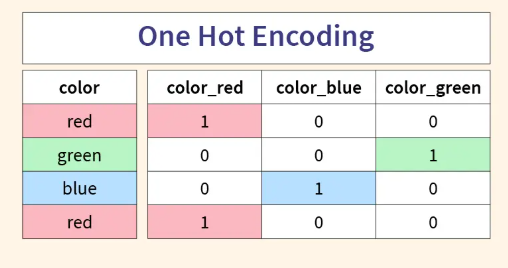

In [ ]:
def onehot_encoding(data, n_classes=10):
  return np.array(tf.one_hot(data, depth=n_classes))

In [ ]:
# Převed data na one-hot encoding
y_train_onehot = onehot_encoding(y_train)
y_test_onehot = onehot_encoding(y_test)

In [ ]:
y_train_onehot[0]

array([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.], dtype=float32)

In [ ]:
y_train[0]

np.uint8(5)

### Zkrácení datasetu
V případě neuronových síťí **není** obvykle chtěné krátit dataset ❗ Chceme pokud možno co nejvíce trénovacích a testovacích dat.



# ⭐ Vytvoření modelů
Dataset je připraven, nyní nám stačí vytvořit, natrénovat a otestovat model.  

### 🧭 **Sekvenční** X **Manuální**
TensorFlow umožňuje zápis neuronových síťí buď sekvenční formou, nebo manuláně skládat vrstvu za vrstvou. Ukážeme si oba tyto přístupy.

#### Sekvenční přístup

In [ ]:
# Definice modelu
model = tf.keras.Sequential([
    tf.keras.layers.Dense(units=128, activation='relu', input_shape=(28*28,)),
    tf.keras.layers.Dense(units=64, activation='relu'),
    tf.keras.layers.Dense(units=10, activation='softmax')
])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/dense.py:93: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

#### Manuální přístup

In [ ]:
 # Vytvoření modelu

 # Vstupní vrstva
input_layer = tf.keras.layers.Input(shape=((28*28,)))
 # Skryté vrstvy
x = tf.keras.layers.Dense(units=128, activation='relu')(input_layer)
x = tf.keras.layers.Dense(units=64, activation='relu')(x)
 # Výstupní vrstva
output_layer = tf.keras.layers.Dense(units=10, activation='softmax')(x)

# Sestavení modelu
model = tf.keras.Model(input_layer, output_layer)
model.summary()

Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

**Rozbor modelu:**
- `Sequential`: obalí vrstvy a automaticky z nich vytvoří sekvenci -> `model`
- `Dense`: "hustě propojená vrstva", základní klasická vrstva neuronové sítě, všechny neuronony jsou propojené na všechny [(doc)](https://www.tensorflow.org/api_docs/python/tf/keras/layers/Dense)
  - *units* : počet neuronů v této vrstvě
  - *activation*: typ použité aktivační funkce
  - *input_shape*: vstupní tvar dat, značí že tato vrstva je vstupní
  - *softmax*: dává se do výstupní vrstvy, transformuje výstup na distribuci pravděpodobnosti jednotlivých tříd, v našem případě jde o 10 tříd.

- `summary` : vypíše strukturu modelu

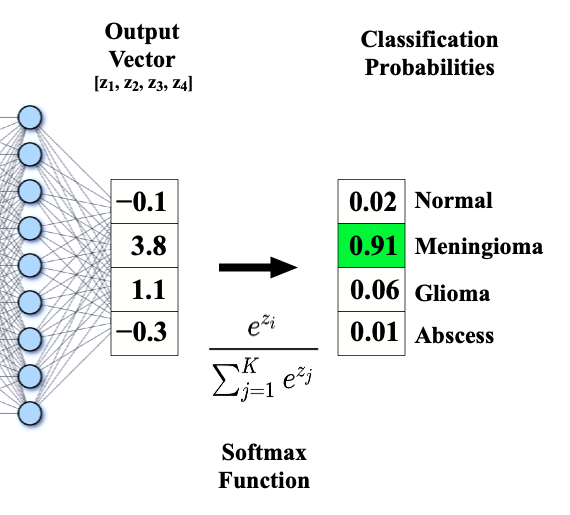

### 💪 Kompilace a trénování modelu

In [ ]:
# Kompilace modelu
model.compile(optimizer=tf.keras.optimizers.Adam(),
              loss=tf.keras.losses.CategoricalCrossentropy(from_logits=False),
              metrics=[tf.keras.metrics.categorical_accuracy])

In [ ]:
# Kompilace modelu - pomocí textových aliasů
model.compile(optimizer='adam',
              loss='categorical_crossentropy',
              metrics=['accuracy'])

**Rozbor kompilace modelu:**
- *optimizer*: optimalizuje váhy modelu v závislosti na ztrátě
- *loss*: funkce která počítá ztrátu
  - *CategoricalCrossentropy*: značí že očekáváme klasifikaci dat do kategorií, kde každá kategorie bude označena jako one-hot.
- *metrics*: metriky které chceme na modelu dodatečně měřit, může jít výkon a nebo o přesnost, chybovost atd...

In [ ]:
# Trénování modelu
epochs = 10
history = model.fit(X_train, y_train_onehot, epochs=epochs, batch_size=64)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - accuracy: 0.8621 - loss: 0.4968
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9651 - loss: 0.1153
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9767 - loss: 0.0759
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9829 - loss: 0.0571
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9860 - loss: 0.0439
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9898 - loss: 0.0333
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9918 - loss: 0.0270
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9931 - loss: 0.0215
Epoch 9/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 11s 6ms/step - accuracy: 0.9944 - loss: 0.0174
Epoch 10/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9943 - loss: 0.0166


✍ *Vsuvka:* Trénování modelu zabere nějaký čas, je třeba pár min počkat ⏰

**Rozbor trénování modelu:**
- `history`: zde se ukládá historie trénování v jednotlivých epochách
- *epochs*: počet epoch pro treénování modelu (víc nemusí být lepší)
- *batch_size*: velikost dávky, kolik dat (počet záznamů/trénovacích jednotek/obrázků) má model projít než upraví váhy - *jak dlouhá má být jedna epocha*.

### ✅ Testování modelu
Model otestujeme klasickou funkcí `score` nebo externí metrikou.

In [ ]:
# Vyhodnocení přesnosti modelu
loss, categorical_accuracy = model.evaluate(X_test, y_test_onehot)
loss, categorical_accuracy

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - accuracy: 0.9753 - loss: 0.0924


(0.07805495709180832, 0.978600025177002)

### 📈 Metriky
Pro lepší přehled o průběhu trénování modelu si vykreslíme metriky.

In [ ]:
def show_history(history, ignore_val = True):
    plt.figure()
    for key in history.history.keys():
      if key.find("val") != -1 and ignore_val:
        continue
      plt.plot(history.epoch, history.history[key], label=key)
    plt.legend()
    plt.tight_layout()

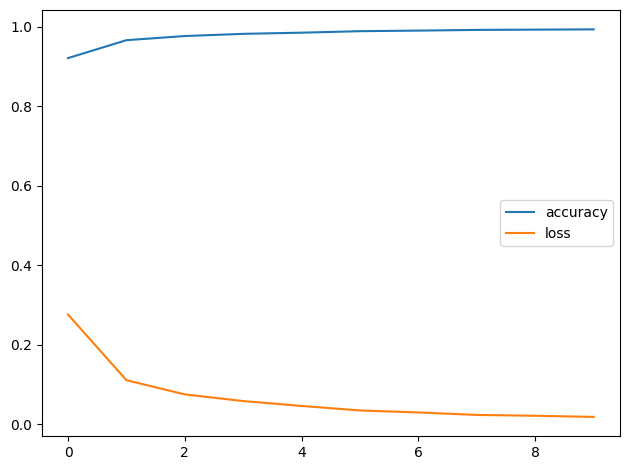

In [ ]:
show_history(history)

✍ *Vsuvka:* Tento model je již téměř dokonalý. Cílem trénování je především snižovat ztrátu! ↘ **Dokud se snižuje ztráta, znamená to že model se stále zlepšuje!**

### 👁️ Predikce:

In [ ]:
# Použiji testovací data které model nezná a predikuji 16 záznamů
y_pred = model.predict(X_test[:16])

#Kontrola tvaru
y_pred.shape

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 110ms/step


(16, 10)

In [ ]:
# Náhled jednoho záznamu
y_pred[0]

array([3.9654313e-10, 4.3697628e-09, 4.8242477e-08, 3.2740499e-07,
       8.6152635e-10, 1.1461226e-10, 1.7062791e-17, 9.9999899e-01,
       5.1571885e-07, 9.2089820e-08], dtype=float32)

✍ *Vsuvka:* Jak vydíme, **predikce nevypadá úplně tak jak bychom chtěli** - místo čísla classy jsme obdrželi **distribuci pravděpodobnosti** pro jednotlivé třídy poskytnuté funkcí `softmax`.

In [ ]:
def probs_to_classes(probs):
  classses = []
  for prob in probs:
    classses.append(np.argmax(prob))
  return classses

In [ ]:
y_test[0]

np.uint8(7)

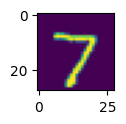

In [ ]:
plt.figure(figsize=(1,1))
plt.imshow(X_test[0].reshape(28, 28))

In [ ]:
# Konvertuj
y_pred_classes = probs_to_classes(y_pred)
y_pred_classes

[np.int64(7),
 np.int64(2),
 np.int64(1),
 np.int64(0),
 np.int64(4),
 np.int64(1),
 np.int64(4),
 np.int64(9),
 np.int64(5),
 np.int64(9),
 np.int64(0),
 np.int64(6),
 np.int64(9),
 np.int64(0),
 np.int64(1),
 np.int64(5)]

In [ ]:
y_test[:16]

array([7, 2, 1, 0, 4, 1, 4, 9, 5, 9, 0, 6, 9, 0, 1, 5], dtype=uint8)

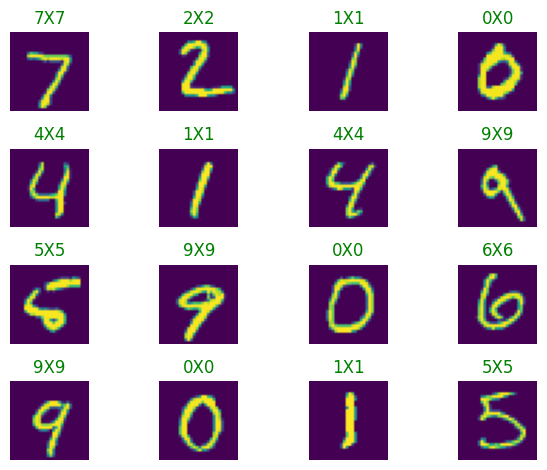

In [ ]:
for i in range(16):
    plt.subplot(4, 4, i+1)
    # Musím provést reversní reshape dat zpět na rozměr 32x32x3
    plt.imshow(X_test[i].reshape(28, 28))
    pred_val = y_pred_classes[i]
    true_val = y_test[i]
    # c = "b" if y_pred[i] == y_test[i] else "r" - inline ternární operátor který přepíná barvu mezi g (green) a r (red)
    plt.title(f'{pred_val}X{true_val}', c = "g" if y_pred_classes[i] == y_test[i] else "r")
    plt.axis('off')

# Zarovná layout
plt.tight_layout()

In [ ]:
# Confusion matrix for model
from sklearn.metrics import confusion_matrix

# For all test data
y_pred = model.predict(X_test)
y_pred_classes = probs_to_classes(y_pred)
cm = confusion_matrix(y_test, y_pred_classes)
# Plot
plt.figure(figsize=(10,10))
sns.heatmap(cm, annot=True, fmt='g', cmap='Blues')
plt.xlabel('Predicted')
plt.ylabel('True')

## 🖌️**Canvas**

In [ ]:
!pip install ipycanvas

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 143.0/143.0 kB 4.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.6/1.6 MB 28.5 MB/s eta 0:00:00


In [ ]:
from google.colab import output
output.enable_custom_widget_manager()

In [ ]:
import numpy as np
from PIL import Image, ImageOps
from IPython.display import display, HTML, Javascript
from google.colab.output import eval_js

def get_drawing_robust(width=200, height=200):
    """
    Robustní verze pro opakované spuštění.
    """
    # Vygeneruje unikátní ID pro prvky, aby se předešlo konfliktům
    container_id = f"drawing_container_{np.random.randint(100000)}"

    # HTML kód s div pro umístění plátna a tlačítka
    html_code = f"""
        <div id="{container_id}">
            <canvas id="canvas_{container_id}" width="{width}" height="{height}" style="border: 1px solid black;"></canvas>
            <button id="button_{container_id}">Uložit kresbu a pokračovat</button>
        </div>
    """
    display(HTML(html_code))

    # JavaScript pro kreslení a získání dat
    js_code = f"""
        (function() {{
            const container = document.getElementById('{container_id}');
            const canvas = document.getElementById('canvas_{container_id}');
            const button = document.getElementById('button_{container_id}');
            const ctx = canvas.getContext('2d');

            // ... (Zbytek JS kódu pro kreslení je stejný) ...
            ctx.lineWidth = 15;
            ctx.lineCap = 'round';
            ctx.strokeStyle = 'black';
            ctx.fillStyle = 'white';
            ctx.fillRect(0, 0, canvas.width, canvas.height);

            let isDrawing = false;
            canvas.addEventListener('mousedown', (e) => {{
                isDrawing = true;
                ctx.beginPath();
                ctx.moveTo(e.offsetX, e.offsetY);
            }});
            canvas.addEventListener('mousemove', (e) => {{
                if (isDrawing) {{
                    ctx.lineTo(e.offsetX, e.offsetY);
                    ctx.stroke();
                }}
            }});
            canvas.addEventListener('mouseup', () => {{ isDrawing = false; }});
            canvas.addEventListener('mouseout', () => {{ isDrawing = false; }});
            // -----------------------------------------------------------------

            return new Promise(resolve => {{
                button.onclick = () => {{
                    const dataUrl = canvas.toDataURL('image/png');
                    // Odstraní celý kontejner, aby se vyčistila buňka
                    container.remove();
                    resolve(dataUrl);
                }};
            }});
        }})() // Okamžité spuštění anonymní funkce
    """

    data_url = eval_js(js_code)
    # Zpracování dataUrl (dekódování, konverze na BW pole) - STEJNÉ JAKO PŘEDTÍM
    import base64
    from io import BytesIO
    from PIL import Image

    header, encoded = data_url.split(",", 1)
    img_data = base64.b64decode(encoded)
    img = Image.open(BytesIO(img_data))
    img = img.resize((28, 28)).convert('L')
    # Invert image
    img = ImageOps.invert(img)
    bw_array = np.array(img)

    return bw_array

# --- Zkusit spustit robustní verzi ---
# print("Nakreslete něco do rámečku níže (ideálně číslici) a klikněte na 'Uložit'.")
# try:
#     drawing_data_bw = get_drawing_robust(width=200, height=200)
#     print(f"Tvar pole: {drawing_data_bw.shape}")
# except Exception as e:
#     print(f"Chyba při spuštění: {e}")

In [ ]:
print("Nakreslete něco do rámečku níže (ideálně číslici) a klikněte na 'Uložit'.")
try:
    drawing_data_bw = get_drawing_robust(width=280, height=280)
    print(f"Tvar pole: {drawing_data_bw.shape}")
except Exception as e:
    print(f"Chyba při spuštění: {e}")

Nakreslete něco do rámečku níže (ideálně číslici) a klikněte na 'Uložit'.


Tvar pole: (28, 28)


In [ ]:
drawing_data_bw

array([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   5,   5,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,  31, 200, 162,  56, 157,
        164,  46,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  25, 211, 255, 254, 255, 255,
        255, 213,  12,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0, 161, 255, 236, 255, 217,  62,
        105, 255,  99,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  33, 250, 167,  45,  99,  19,   0,
         13, 232, 195,   2,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0, 107, 255,  73,   0,   0,   0,   0,
          0, 152, 251,  32,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0, 188, 236,  15,   0,   0,   0,   0,
          0,  83, 255,  83,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,  25, 245, 169,   0,   0,   0,   0,   0,
          0,  43, 255, 121,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,  76, 255,  94,   0,   0,   0,   0,   0,
          0,  24, 248, 149,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 140, 251,  38,   0,   0,   0,   0,   0,
          0,  19, 245, 157,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 182, 229,   8,   0,   0,   0,   0,   0,
          0,  20, 245, 156,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 183, 226,   7,   0,   0,   0,   0,   0,
          0,  20, 245, 156,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 175, 234,  12,   0,   0,   0,   0,   0,
          0,  20, 245, 156,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0, 127, 255,  46,   0,   0,   0,   0,   0,
          0,  19, 245, 157,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,  58, 255, 147,   0,   0,   0,   0,   0,
          0,  26, 249, 148,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   3, 182, 255,  91,   0,   0,   0,   0,
          0,  51, 255, 109,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,  33, 218, 255, 148,  15,   0,   0,
          0,  99, 255,  72,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,  25, 169, 255, 209,  82,  40,
         82, 231, 227,  20,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0, 108, 237, 255, 255,
        255, 233,  66,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,  28,  97, 129,
         97,  28,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
          0,   0],
       [  0,   0,   0,   0,   0,   0,   

In [ ]:
drawing_data_bw_norm = drawing_data_bw.reshape(1, 28*28) / 255
predicted = model.predict(drawing_data_bw_norm)
predicted

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


array([[8.5762152e-03, 1.9406939e-01, 1.2915526e-01, 2.2682072e-01,
        1.4596669e-03, 8.7338965e-04, 1.0091074e-01, 2.9985461e-01,
        3.8237747e-02, 4.2275908e-05]], dtype=float32)

In [ ]:
predicted_num = probs_to_classes(predicted)[0]
predicted_conf = max(predicted[0])*100
print(f"Your handcraft number is predicted as number {predicted_num}, with confidence {predicted_conf:.2f}%")

Your handcraft number is predicted as number 7, with confidence 29.99%
